In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [75]:
house_data = pd.read_csv('train.csv')
house_data.shape

(1460, 81)

In [76]:
house_data['SalePrice'].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

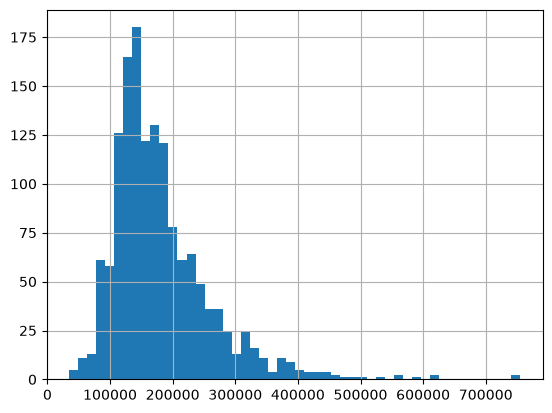

In [77]:
house_data['SalePrice'].hist(bins=50)
plt.show()

In [78]:
missing = house_data.isnull().sum()
missing[missing > 0].sort_values(ascending = False)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [79]:
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtExposure', 'BsmtFinType2', 'BsmtQual', 'BsmtCond', 'BsmtFinType1']

for col in none_cols:
    house_data[col] = house_data[col].fillna('None')

house_data['MasVnrArea'] = house_data['MasVnrArea'].fillna(0)
house_data['GarageYrBlt'] = house_data['GarageYrBlt'].fillna(house_data['YearBuilt'])
house_data['LotFrontage'] = house_data['LotFrontage'].fillna(house_data['LotFrontage'].median())
house_data['Electrical'] = house_data['Electrical'].fillna(house_data['Electrical'].mode()[0])

In [80]:
house_data.isnull().sum().sum()

np.int64(0)

In [81]:
text_cols = house_data.select_dtypes(exclude='number').columns
num_cols = house_data.select_dtypes(include='number').columns
print("Text columns:", len(text_cols))
print("Number columns:", len(num_cols))

Text columns: 43
Number columns: 38


In [82]:
corr = house_data.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False)
corr.head(11)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
GarageYrBlt     0.508043
Name: SalePrice, dtype: float64

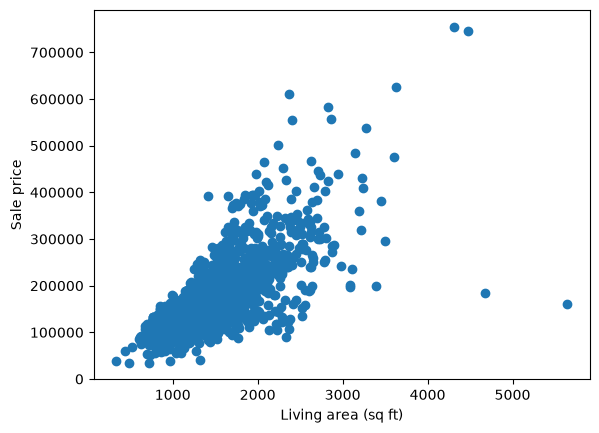

In [83]:
plt.scatter(house_data['GrLivArea'], house_data['SalePrice'])
plt.xlabel('Living area (sq ft)')
plt.ylabel('Sale price')
plt.show()

In [84]:
house_data = house_data[~((house_data['GrLivArea'] > 4000) & (house_data['SalePrice'] < 300000))]
house_data.shape

(1458, 81)

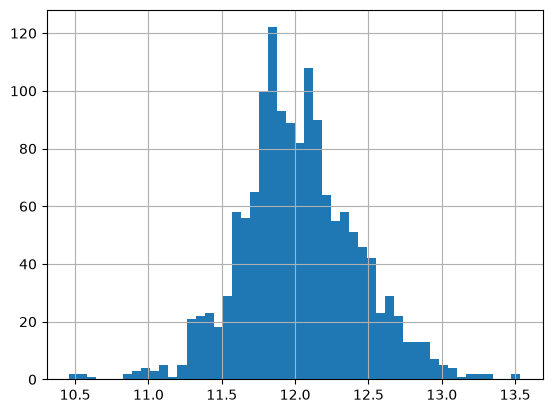

In [85]:
Y = np.log1p(house_data['SalePrice'])

Y.hist(bins=50)
plt.show()

In [86]:
X = house_data.drop(columns=['Id', 'SalePrice'])
X = pd.get_dummies(X)
X.shape

(1458, 301)

In [87]:
list(X.columns)

['MSSubClass',
 'LotFrontage',
 'LotArea',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'MasVnrArea',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'TotRmsAbvGrd',
 'Fireplaces',
 'GarageYrBlt',
 'GarageCars',
 'GarageArea',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 '3SsnPorch',
 'ScreenPorch',
 'PoolArea',
 'MiscVal',
 'MoSold',
 'YrSold',
 'MSZoning_C (all)',
 'MSZoning_FV',
 'MSZoning_RH',
 'MSZoning_RL',
 'MSZoning_RM',
 'Street_Grvl',
 'Street_Pave',
 'Alley_Grvl',
 'Alley_None',
 'Alley_Pave',
 'LotShape_IR1',
 'LotShape_IR2',
 'LotShape_IR3',
 'LotShape_Reg',
 'LandContour_Bnk',
 'LandContour_HLS',
 'LandContour_Low',
 'LandContour_Lvl',
 'Utilities_AllPub',
 'Utilities_NoSeWa',
 'LotConfig_Corner',
 'LotConfig_CulDSac',
 'LotConfig_FR2',
 'LotConfig_FR3',
 'LotConfig_Inside',
 'LandSlope_

In [88]:
pd.set_option('display.max_columns', None)
X.head()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,MSZoning_C (all),MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM,Street_Grvl,Street_Pave,Alley_Grvl,Alley_None,Alley_Pave,LotShape_IR1,LotShape_IR2,LotShape_IR3,LotShape_Reg,LandContour_Bnk,LandContour_HLS,LandContour_Low,LandContour_Lvl,Utilities_AllPub,Utilities_NoSeWa,LotConfig_Corner,LotConfig_CulDSac,LotConfig_FR2,LotConfig_FR3,LotConfig_Inside,LandSlope_Gtl,LandSlope_Mod,LandSlope_Sev,Neighborhood_Blmngtn,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,Neighborhood_Crawfor,Neighborhood_Edwards,Neighborhood_Gilbert,Neighborhood_IDOTRR,Neighborhood_MeadowV,Neighborhood_Mitchel,Neighborhood_NAmes,Neighborhood_NPkVill,Neighborhood_NWAmes,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,Condition1_Artery,Condition1_Feedr,Condition1_Norm,Condition1_PosA,Condition1_PosN,Condition1_RRAe,Condition1_RRAn,Condition1_RRNe,Condition1_RRNn,Condition2_Artery,Condition2_Feedr,Condition2_Norm,Condition2_PosA,Condition2_PosN,Condition2_RRAe,Condition2_RRAn,Condition2_RRNn,BldgType_1Fam,BldgType_2fmCon,BldgType_Duplex,BldgType_Twnhs,BldgType_TwnhsE,HouseStyle_1.5Fin,HouseStyle_1.5Unf,HouseStyle_1Story,HouseStyle_2.5Fin,HouseStyle_2.5Unf,HouseStyle_2Story,HouseStyle_SFoyer,HouseStyle_SLvl,RoofStyle_Flat,RoofStyle_Gable,RoofStyle_Gambrel,RoofStyle_Hip,RoofStyle_Mansard,RoofStyle_Shed,RoofMatl_CompShg,RoofMatl_Membran,RoofMatl_Metal,RoofMatl_Roll,RoofMatl_Tar&Grv,RoofMatl_WdShake,RoofMatl_WdShngl,Exterior1st_AsbShng,Exterior1st_AsphShn,Exterior1st_BrkComm,Exterior1st_BrkFace,Exterior1st_CBlock,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing,Exterior2nd_AsbShng,Exterior2nd_AsphShn,Exterior2nd_Brk Cmn,Exterior2nd_BrkFace,Exterior2nd_CBlock,Exterior2nd_CmentBd,Exterior2nd_HdBoard,Exterior2nd_ImStucc,Exterior2nd_MetalSd,Exterior2nd_Other,Exterior2nd_Plywood,Exterior2nd_Stone,Exterior2nd_Stucco,Exterior2nd_VinylSd,Exterior2nd_Wd Sdng,Exterior2nd_Wd Shng,MasVnrType_BrkCmn,MasVnrType_BrkFace,MasVnrType_None,MasVnrType_Stone,ExterQual_Ex,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,ExterCond_Ex,ExterCond_Fa,ExterCond_Gd,ExterCond_Po,ExterCond_TA,Foundation_BrkTil,Foundation_CBlock,Foundation_PConc,Foundation_Slab,Foundation_Stone,Foundation_Wood,BsmtQual_Ex,BsmtQual_Fa,BsmtQual_Gd,BsmtQual_None,BsmtQual_TA,BsmtCond_Fa,BsmtCond_Gd,BsmtCond_None,BsmtCond_Po,BsmtCond_TA,BsmtExposure_Av,BsmtExposure_Gd,BsmtExposure_Mn,BsmtExposure_No,BsmtExposure_None,BsmtFinType1_ALQ,BsmtFinType1_BLQ,BsmtFinType1_GLQ,BsmtFinType1_LwQ,BsmtFinType1_None,BsmtFinType1_Rec,BsmtFinType1_Unf,BsmtFinType2_ALQ,BsmtFinType2_BLQ,BsmtFinType2_GLQ,BsmtFinType2_LwQ,BsmtFinType2_None,BsmtFinType2_Rec,BsmtFinType2_Unf,Heating_Floor,Heating_GasA,Heating_GasW,Heating_Grav,Heating_OthW,Heating_Wall,HeatingQC_Ex,HeatingQC_Fa,HeatingQC_Gd,HeatingQC_Po,HeatingQC_TA,CentralAir_N,CentralAir_Y,Electrical_FuseA,Electrical_FuseF,Electrical_FuseP,Electrical_Mix,Electrical_SBrkr,KitchenQual_Ex,KitchenQual_Fa,KitchenQual_Gd,KitchenQual_TA,Functional_Maj1,Functional_Maj2,Functional_Min1,Functional_Min2,Functional_Mod,Functional_Sev,Functional_Typ,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,GarageType_2Types,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_CarPort,GarageType_Detchd,GarageType_None,Gara

In [89]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

lr = LinearRegression()
scores = cross_val_score(lr, X, Y, cv=5, scoring='neg_root_mean_squared_error')
print(-scores.mean())

0.12779724987115715


In [90]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

models = {
    "Linear": LinearRegression(),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Forest": RandomForestRegressor(n_estimators=300, random_state=0),
    "Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=0),
    "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, random_state=0),
}

for name, m in models.items():
    scores = cross_val_score(m, X, Y, cv=5, scoring='neg_root_mean_squared_error')
    print(name, round(-scores.mean(), 4))

Linear 0.1278
Ridge 0.1257
Forest 0.1376
Boosting 0.1204
XGBoost 0.118


In [91]:
test = pd.read_csv('test.csv')

for col in none_cols:
    test[col] = test[col].fillna('None')

test['MasVnrArea'] = test['MasVnrArea'].fillna(0)
test['GarageYrBlt'] = test['GarageYrBlt'].fillna(test['YearBuilt'])
test['LotFrontage'] = test['LotFrontage'].fillna(house_data['LotFrontage'].median())

num = test.select_dtypes(include='number').columns
test[num] = test[num].fillna(0)

txt = test.select_dtypes(exclude='number').columns
for col in txt:
    test[col] = test[col].fillna(house_data[col].mode()[0])

test.isnull().sum().sum()

np.int64(0)

In [92]:
X_test = pd.get_dummies(test.drop(columns=['Id']))
X_test = X_test.reindex(columns=X.columns, fill_value=0)
X_test.shape

(1459, 301)

In [93]:
final_model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, random_state=0)
final_model.fit(X, Y)

preds = np.expm1(final_model.predict(X_test))

submission = pd.DataFrame({'Id': test['Id'], 'SalePrice': preds})
submission.to_csv('submission.csv', index=False)
print(submission.shape)
submission.head()

(1459, 2)


,Id,SalePrice
0,1461,120843.859375
1,1462,151850.062500
2,1463,183552.453125
3,1464,190697.734375
4,1465,185093.906250


In [94]:
Which clue moves with the price?
Correlation with price on 200 practice houses. Higher bar means a stronger clue.

TotalSF
0.83
TotalBsmtSF
0.75
GrLivArea
0.70
1stFlrSF
0.69
2ndFlrSF
0.34
TotalSF built

SyntaxError: invalid decimal literal (47348032.py, line 10)

In [ ]:
def add_features(df):
    df = df.copy()
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalBath'] = df['FullBath'] + 0.5 * df['HalfBath'] + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath']
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    df['TotalPorch'] = df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch'] + df['ScreenPorch'] + df['WoodDeckSF']
    df['MSSubClass'] = df['MSSubClass'].astype(str)
    return df

In [ ]:
house_fe = add_features(house_data)
test_fe = add_features(test)

X2 = pd.get_dummies(house_fe.drop(columns=['Id', 'SalePrice']))
X2_test = pd.get_dummies(test_fe.drop(columns=['Id'])).reindex(columns=X2.columns, fill_value=0)

print(X2.shape, X2_test.shape)

In [ ]:
house_fe[['TotalSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'GrLivArea', 'OverallQual', 'SalePrice']].corr()['SalePrice'].sort_values(ascending=False)

In [ ]:
xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, random_state=0)

old = -cross_val_score(xgb, X, Y, cv=5, scoring='neg_root_mean_squared_error').mean()
new = -cross_val_score(xgb, X2, Y, cv=5, scoring='neg_root_mean_squared_error').mean()

print("Old features:", round(old, 4))
print("New features:", round(new, 4))

In [ ]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=10))

old_r = -cross_val_score(ridge, X, Y, cv=5, scoring='neg_root_mean_squared_error').mean()
new_r = -cross_val_score(ridge, X2, Y, cv=5, scoring='neg_root_mean_squared_error').mean()

print("Ridge old:", round(old_r, 4))
print("Ridge new:", round(new_r, 4))

In [ ]:
X3 = X2.copy()
X3['QualxSF'] = house_fe['OverallQual'] * house_fe['TotalSF']

for name, data in [("X2", X2), ("X3", X3)]:
    r = -cross_val_score(ridge, data, Y, cv=5, scoring='neg_root_mean_squared_error').mean()
    x = -cross_val_score(xgb, data, Y, cv=5, scoring='neg_root_mean_squared_error').mean()
    print(name, "Ridge:", round(r, 4), " XGBoost:", round(x, 4))
    

In [95]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_squared_error

ridge = make_pipeline(StandardScaler(), Ridge(alpha=10))
xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, random_state=0)

p_ridge = cross_val_predict(ridge, X, Y, cv=5)
p_xgb = cross_val_predict(xgb, X, Y, cv=5)

for w in [0, 0.2, 0.3, 0.4, 0.5, 0.7, 1]:
    blend = w * p_ridge + (1 - w) * p_xgb
    print(w, round(np.sqrt(mean_squared_error(Y, blend)), 4))

0 0.1182
0.2 0.1141
0.3 0.1131
0.4 0.1128
0.5 0.1133
0.7 0.1165
1 0.1261


In [96]:
ridge.fit(X, Y)
xgb.fit(X, Y)

p_test = 0.4 * ridge.predict(X_test) + 0.6 * xgb.predict(X_test)
preds = np.expm1(p_test)

submission = pd.DataFrame({'Id': test['Id'], 'SalePrice': preds})
submission.to_csv('submission_blend.csv', index=False)
print(submission.shape)
submission.head()

(1459, 2)


,Id,SalePrice
0,1461,120385.932021
1,1462,156613.933080
2,1463,183566.037736
3,1464,195355.434611
4,1465,188162.719008


In [97]:
from sklearn.neighbors import KNeighborsRegressor

knn_raw = KNeighborsRegressor(n_neighbors=10)
knn_scaled = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10))

for name, m in [("No scaling", knn_raw), ("With scaling", knn_scaled)]:
    s = -cross_val_score(m, X, Y, cv=5, scoring='neg_root_mean_squared_error').mean()
    print(name, round(s, 4))

No scaling 0.2257
With scaling 0.1956


In [98]:
for k in [1, 3, 5, 10, 15, 25, 50, 100]:
    m = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    s = -cross_val_score(m, X, Y, cv=5, scoring='neg_root_mean_squared_error').mean()
    print(k, round(s, 4))

1 0.2478
3 0.2015
5 0.1962
10 0.1956
15 0.1988
25 0.2052
50 0.2196
100 0.24


In [99]:
top = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'YearBuilt', 'YearRemodAdd']

m = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10))
s = -cross_val_score(m, X[top], Y, cv=5, scoring='neg_root_mean_squared_error').mean()
print("KNN with 8 clues:", round(s, 4))

KNN with 8 clues: 0.1646
